## January 2026 
In this file I will test the output of the new version of CosmoTherm FH. <br>
I will look at the anisotropic spectral distortions sourced by photon to dark photon conversion in absence of anisotropic heating, using the transfer functions. <br>


In [38]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import tol_colors as tc

import tools
import my_plot as mplt
plt.rcParams['font.size']=22 # Default font size for text in plots, legend
font_title = 30
font_xylabels = 26
font_ticks = 26

In [39]:
def extract_custom_state_from_files(folder_path, ell, pattern="custom_state_kv_001_yn_aniso_system-all_wG.dat_ymax15_lmax25_adiabatic.dat"):
    """Extract custom transfer function data from files in a folder """
    folder = Path(folder_path) / "batch" / "FH" 
    file_path = next(folder.glob(pattern))
    
    theta = [[] for _ in range(ell+1)]
    mu = [[] for _ in range(ell+1)]
    y = [[] for _ in range(ell+1)]
    z = []
    
    data = np.loadtxt(file_path, comments='#')  
    z.extend(data[:, 0])  # First column is redshift
    for i in range(ell+1):
        theta[i].extend(data[:, 1+i*(ell)])   # All theta values from column 1 and multiples of it
        print( " theta ", i, "comes from column ", 1+i*(ell))
        y[i].extend(data[:, 2+i*(ell)])       # All y values from column 2 and multiples of it
        print( " y ", i, "comes from column ", 2+i*(ell))
        mu[i].extend(data[:, 3+i*(ell)])  # All mu values from column 3 and multiples of it
        print( " mu ", i, "comes from column ", 3+i*(ell))
    
    return z, np.array(theta), np.array(y), np.array(mu)

In [40]:
def extract_tightcoupling_approx(folder_path,ell,ell_max,k ):
    """Extract tight coupling approximation data from files in a folder """
    folder = Path(folder_path) / "batch" / "FH" / "yn_T_aniso_system"
    file_path = next(folder.glob(f"custom_redshift_info_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic.dat"))
    
    z = []
    theta = [[] for _ in range(ell+1)]
    mu = [[] for _ in range(ell+1)]
    y = [[] for _ in range(ell+1)]
    
    data = np.loadtxt(file_path, comments='#') 
    z.extend(data[:, 0])  # First column is redshift
    for i in range(ell+1):
        #print( " theta ", i, "comes from column ", 1+i)
        theta[i].extend(data[:,1+i])
        #print( " y ", i, "comes from column ", 4+i)
        y[i].extend(data[:, 4+i])
        print( " mu ", i, "comes from column ", 7+i)
        mu[i].extend(data[:, 7+i])
     
    
    return np.array(z), np.array(theta), np.array(y), np.array(mu)

In [41]:
def extract_state_scattering_basis(folder_path, ell, ell_max, k, basis="scattering"):
    """Extract scattering basis transfer function data from files in a folder """
    folder = Path(folder_path)
    file_path = []
    file_path2 = []
    # Collect multipole files (0,1,2,...)
    for i in range(ell+1):
        file_path.append(next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic_scattering-basis_{i}.dat")))
        # theta values always come from the computational basis for the scattering
        file_path2.append(next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic_computation-basis_{i}.dat"))) 
    # Collect background file
    bg_file = next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic_scattering-basis_bg.dat"))
    bg_file2 = next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic.dat"))

    dtheta = [[] for _ in range(ell+1)]  # To store corrections to the monopole, will be filled from bg_file2
    theta = [[] for _ in range(ell+2)]
    mu = [[] for _ in range(ell+2)]
    y = [[] for _ in range(ell+2)]
    a = []

    # Read header to find theta_corr_0 column (format: "name [col_num]")
    with open(bg_file2, 'r') as f:
        header_line = f.readline().strip('# \n')
        header = header_line.split()
    # Find column index for theta_corr_0: look for "theta_corr_0", then get number from next element "[N]"
    idx = header.index("theta_corr_0")
    theta_corr_col = int(header[idx + 1].strip('[]')) - 1  # Convert to 0-indexed

    # First: background
    data_bg = np.loadtxt(bg_file, comments='#')
    data_theta_bg = np.loadtxt(bg_file2, comments='#')
    
    a.extend(data_bg[:, 0])  # First column is redshift (only read once)
    theta[0].extend(data_theta_bg[:, 1])
    y[0].extend(data_bg[:, 2])
    mu[0].extend(data_bg[:, 9])

    # Then: multipoles
    for i in range(ell+1):
        data = np.loadtxt(file_path[i], comments='#')
        data_theta = np.loadtxt(file_path2[i], comments='#')
        theta[i+1].extend(data_theta[:, 1])
        y[i+1].extend(data[:, 2])
        mu[i+1].extend(data[:, 9])
        dtheta[i].extend(data_theta_bg[:, theta_corr_col+i])
    
    # Load corrections to the monopole from the background file (dynamically found column)
    

    return a, np.array(theta), np.array(y), np.array(mu), np.array(dtheta)

In [42]:
ell = 2
kv_values = [ "002", "003", "004"]
kv_values_Mpc = {"001" : 1, "002" : 0.1, "003" : 0.01, "004" : 0.001}

zcon = [5.0e6,5.0e5, 5e4, 5e3]

In [43]:
z = []
dtheta_tc0 = []
y_tc0 = []
mu_tc0 = []



for kv in kv_values:
    z, _theta, _y, _mu = extract_tightcoupling_approx("../Data/Dark-photons/outputs_dp_tc2/outputs-dp1.0_ph",ell,150,kv )
    dtheta_tc0.append(_theta)
    y_tc0.append(_y)
    mu_tc0.append(_mu)
  


 mu  0 comes from column  7
 mu  1 comes from column  8
 mu  2 comes from column  9
 mu  0 comes from column  7
 mu  1 comes from column  8
 mu  2 comes from column  9
 mu  0 comes from column  7
 mu  1 comes from column  8
 mu  2 comes from column  9


In [44]:

theta = []
y = []
mu = []
a = []
dtheta = []

for kv in kv_values:
    zt, th, yy, m, dth = extract_state_scattering_basis("../Data/Dark-photons/output_dp_ell/outputs-dp1.0_ph/batch/FH/yn_T_aniso_system", ell, 150, kv )
    #zt, th, yy, m, dth = extract_state_scattering_basis("../Data/Dark-photons/output_dp_tfph2/outputs-dp1.0_ph/batch/FH/yn_T_aniso_system", ell, 150, kv )
    #zt, th, yy, m, dth = extract_state_scattering_basis("../Data/Dark-photons/dp-aniso1.0/", ell, 50, kv )
        
    theta.append(th)
    y.append(yy)
    mu.append(m)
    a.append(zt)    
    dtheta.append(dth)

In [45]:
# Here we want to find the values of the ratio between various plots
# 1) Pre conversion we have theta_bar = dtheta / 3*theta
theta_bar = 1.7*1e-6

_theta_bar = dtheta[0][0]/(theta[0][1]*3)
print("Before the conversion theta_bar is ", _theta_bar[0])

# 3) Compute the index of the array after which the conversion happens (i.e. where zcon is located in the a array)
_zcon = zcon[0]
for i in range(len(a[0])):
    z = 1 / a[0][i] - 1
    if z < _zcon:
        print("Conversion happens at index ", i, " where z is ", z)
        index_conversion = i
        break

# 2) Post conversion we want to look at conversion ratio for the monopole

_ratio0 = (dtheta[0][0]/(3*theta_bar))/theta[0][1]
for i in range(len(_ratio0)):
    print("At index ", i, " the ratio is ", _ratio0[i], f" and z is  {1/a[0][i]-1:.3e}") # we want them to actually match at late times

# 3) We can apply this ratio to also higher multipoles to see if it works there as well (i.e. if the conversion ratio is the same for all multipoles)
# for the monopole is not really working, it looks like there is a shift as well

Before the conversion theta_bar is  1.7073573773400761e-06
Conversion happens at index  251  where z is  4997350.403756009
At index  0  the ratio is  1.0043278690235744  and z is  1.000e+07
At index  1  the ratio is  1.0043278690235744  and z is  9.972e+06
At index  2  the ratio is  1.0043278690235744  and z is  9.945e+06
At index  3  the ratio is  1.0043375750092425  and z is  9.917e+06
At index  4  the ratio is  1.0043506225058487  and z is  9.890e+06
At index  5  the ratio is  1.004363670002455  and z is  9.863e+06
At index  6  the ratio is  1.0043506225058487  and z is  9.836e+06
At index  7  the ratio is  1.0043472809303253  and z is  9.808e+06
At index  8  the ratio is  1.0043538046569234  and z is  9.781e+06
At index  9  the ratio is  1.0043472809303253  and z is  9.754e+06
At index  10  the ratio is  1.0043472809303253  and z is  9.727e+06
At index  11  the ratio is  1.0043472809303253  and z is  9.701e+06
At index  12  the ratio is  1.004343939377037  and z is  9.674e+06
At in

In [69]:
colors = mplt.set_colors(4, palette="dark_photons")
#colors = mplt.set_colors(4, palette="colorblind")


def plot_transfer_functions(a, theta, dtheta, y, mu, colors, zcon, m_dp, dtheta_tc, y_tc, mu_tc):
    num_rows = 5
    num_cols = 3

    fig, ax1 = plt.subplots(num_rows, num_cols, figsize=mplt.set_size(mplt.width*num_rows, 1, (num_rows,num_cols)), sharey='row')
    fig.subplots_adjust(hspace=0, wspace=0)

    for ax in ax1.flat:
        mplt.set_ticks(ax)
        mplt.set_labels(ax, x_label=None, x_log=True, y_label=None, y_log=False, title=None)
        ax.axhline(y=0, color='gray', linewidth=1, linestyle=(0, (5, 3)))
        ax.axvline(x= 1 / (1+zcon), color='dimgray', linestyle=(0, (20, 6)), linewidth=1)
        ax.set_xlim(1e-7, 1e-1)

    # Loop over columns (kv = 002, 003, 004) and rows
    for col in range(len(kv_values)):  # columns for different kv values
        ax1[0, col].plot(a[col], 4.0*theta[col][0]*1e5, label="$4\\Theta^{(0)}$", color=colors[0], linestyle="-")
        ax1[0, col].plot(a[col], 4.0*y[col][0]*1e5, label="$4y^{(0)}$", color=colors[1], linestyle="-")
        ax1[0, col].plot(a[col], 1/1.401*mu[col][0]*1e5, label="$0.714\\mu^{(0)}$", color=colors[2], linestyle="-")
        for ell_idx in range(1, ell+2):  # ell multipoles 1, 2, 3
            i=ell_idx-1
            ax1[1, col].plot(a[col], 4.0*theta[col][ell_idx], label=f"$4\\Theta^{{(1)}}_{ell_idx-1}$", color=colors[i], linestyle="-")
            #ax1[1,col].plot(a[col], 4.0*theta[col][-1]*1e5, label="$4 \\,\\delta \\theta^{{(1)}} \\times 10^5$", color=colors[1],    linestyle="-")
            #ax1[1,col].plot(a[col], 4.0/3.0*theta[col][-1]/theta_bar, label="$\\frac{4}{3} \\frac{\\delta \\theta^{(1)}}{\\bar{\\theta}}$", color=colors[1],    linestyle="-")

            #ax1[1+ell_idx, col].plot(a[col], 4.0*theta[col][ell_idx]*3*theta_bar*(-0.4) *1e5, label=f"$4\\Theta^{{(1)}}_{ell_idx-1}$", color=colors[3], linestyle="-", alpha=0.8)  # tp show the difference between the two
            ax1[1+ell_idx, col].plot(a[col], 4*dtheta[col][ell_idx-1]*1e5, label=f"$4 \\,\\delta \\Theta^{{(1)}}_{ell_idx-1}$", color=colors[0], linestyle="-", alpha=0.8)
            ax1[1+ell_idx, col].plot(a[col], 4*y[col][ell_idx]*1e5, label=f"$4y^{{(1)}}_{ell_idx-1}$", color=colors[1], linestyle="-", alpha=0.8)
            ax1[1+ell_idx, col].plot(a[col], 1/1.401*mu[col][ell_idx]*1e5, label=f"$0.714\\mu^{{(1)}}_{ell_idx-1}$", color=colors[2], linestyle="-", alpha=0.8)

            ax1[1+ell_idx, col].plot(a[col], 4*dtheta_tc[col][ell_idx-1]*1e5, color=colors[0], linestyle="--", alpha=0.8)
            ax1[1+ell_idx, col].plot(a[col], 4*y_tc[col][ell_idx-1]*1e5, color=colors[1], linestyle="--", alpha=0.8)
            ax1[1+ell_idx, col].plot(a[col], 1/1.401*mu_tc[col][ell_idx-1]*1e5, color=colors[2], linestyle="--", alpha=0.8)
        
        

        ax1[0, col].set_title(f"k = {kv_values_Mpc[kv_values[col]]}" "${\\rm Mpc^{-1}}$", fontsize=mplt.font_title)
            

    # Set labels for left column
    ax1[0, 0].set_ylabel("Transfer functions $\\times 10^5$", fontsize=mplt.font_xylabels)
    ax1[1, 0].set_ylabel("Transfer functions", fontsize=mplt.font_xylabels)
    ax1[2, 0].set_ylabel("Transfer functions $\\times 10^5$", fontsize=mplt.font_xylabels)
    ax1[3, 0].set_ylabel("Transfer functions $\\times 10^5$", fontsize=mplt.font_xylabels)


    # Set x-labels for bottom row only
    for col in range(num_cols):
        ax1[num_rows-1, col].set_xlabel("a", fontsize=mplt.font_xylabels)

    # Remove x tick labels for top two rows
    for row in range(num_rows-1):
        for col in range(num_cols):
            ax1[row, col].tick_params(labelbottom=False)

    # Remove y tick labels for middle and right columns
    for row in range(num_rows):
        for col in range(1, num_cols):
            ax1[row, col].tick_params(labelleft=False)    


    # Add legend to first column subplots
    for i in range(num_rows):
        ax1[i, 0].legend()

    # Dynamically place annotation using axis proportions
    xlim = ax1[num_rows-1, num_cols-1].get_xlim()
    ylim = ax1[num_rows-1, num_cols-1].get_ylim()
    x_annot = xlim[0] + 0.005 * (xlim[1] - xlim[0])  # 1% from left
    y_annot = ylim[1] - 0.2 * (ylim[1] - ylim[0])   # 10% from bottom
    ax1[num_rows-1, num_cols-1].annotate(f"$m_{{\\rm dp}}$ = {tools.sci_notation(m_dp)} \n $z_{{\\rm con}}$ = {tools.sci_notation(zcon)} ", xy=(x_annot, y_annot), fontsize=24)

    plt.tight_layout() 
    plt.savefig(f'outputs/transfer_functions_ph_zcon{np.log10(zcon/5):.0f}.pdf', dpi=300, bbox_inches="tight")
    plt.show()

In [47]:
def plot_transfer_functions_diff(a, theta, dtheta, y, mu, colors, zcon, m_dp, dtheta_tc, y_tc, mu_tc):
    num_rows = 4
    num_cols = 3

    fig, ax1 = plt.subplots(num_rows, num_cols, figsize=mplt.set_size(mplt.width*num_rows, 1, (num_rows,num_cols)), sharey='row')
    fig.subplots_adjust(hspace=0, wspace=0)

    for ax in ax1.flat:
        mplt.set_ticks(ax)
        mplt.set_labels(ax, x_label=None, x_log=True, y_label=None, y_log=False, title=None)
        ax.axhline(y=0, color='gray', linewidth=1, linestyle=(0, (5, 3)))
        ax.axvline(x= 1 / (1+zcon), color='dimgray', linestyle=(0, (20, 6)), linewidth=1)
        ax.set_xlim(1e-7, 1e-1)

    # Loop over columns (kv = 002, 003, 004) and rows
    for col in range(len(kv_values)):  # columns for different kv values
        ax1[0, col].plot(a[col], 4.0*theta[col][0]*1e5, label="$4\\Theta^{(0)}$", color=colors[0], linestyle="-")
        ax1[0, col].plot(a[col], 4.0*y[col][0]*1e5, label="$4y^{(0)}$", color=colors[1], linestyle="-")
        ax1[0, col].plot(a[col], 1/1.401*mu[col][0]*1e5, label="$0.714\\mu^{(0)}$", color=colors[2], linestyle="-")
        for ell_idx in range(1, ell+2):  # ell multipoles 1, 2, 3
            i=ell_idx-1
            ax1[1, col].plot(a[col], 4.0*theta[col][ell_idx], label=f"$4\\Theta^{{(1)}}_{ell_idx-1}$", color=colors[i], linestyle="-")
            #ax1[1,col].plot(a[col], 4.0*theta[col][-1]*1e5, label="$4 \\,\\delta \\theta^{{(1)}} \\times 10^5$", color=colors[1],    linestyle="-")
            #ax1[1,col].plot(a[col], 4.0/3.0*theta[col][-1]/theta_bar, label="$\\frac{4}{3} \\frac{\\delta \\theta^{(1)}}{\\bar{\\theta}}$", color=colors[1],    linestyle="-")

            #ax1[1+ell_idx, col].plot(a[col], 4.0*theta[col][ell_idx]*3*theta_bar*(-0.4) *1e5, label=f"$4\\Theta^{{(1)}}_{ell_idx-1}$", color=colors[3], linestyle="-", alpha=0.8)  # tp show the difference between the two
            ax1[1+ell_idx, col].plot(a[col], 4*dtheta[col][ell_idx-1]*1e5-4*dtheta_tc[col][ell_idx-1]*1e5, label=f"$4 \\,\\delta \\Theta^{{(1)}}_{ell_idx-1}$", color=colors[0], linestyle="-", alpha=0.8)
            ax1[1+ell_idx, col].plot(a[col], 4*y[col][ell_idx]*1e5-4*y_tc[col][ell_idx-1]*1e5, label=f"$4y^{{(1)}}_{ell_idx-1}$", color=colors[1], linestyle="-", alpha=0.8)
            ax1[1+ell_idx, col].plot(a[col], 1/1.401*mu[col][ell_idx]*1e5-1/1.401*mu_tc[col][ell_idx-1]*1e5, label=f"$0.714\\mu^{{(1)}}_{ell_idx-1}$", color=colors[2], linestyle="-", alpha=0.8)

        

        ax1[0, col].set_title(f"k = {kv_values_Mpc[kv_values[col]]}" "${\\rm Mpc^{-1}}$", fontsize=mplt.font_title)
            

    # Set labels for left column
    ax1[0, 0].set_ylabel("Transfer functions $\\times 10^5$", fontsize=mplt.font_xylabels)
    ax1[1, 0].set_ylabel("Transfer functions", fontsize=mplt.font_xylabels)
    ax1[2, 0].set_ylabel("Transfer functions $\\times 10^5$", fontsize=mplt.font_xylabels)
    ax1[3, 0].set_ylabel("Transfer functions $\\times 10^5$", fontsize=mplt.font_xylabels)


    # Set x-labels for bottom row only
    for col in range(num_cols):
        ax1[num_rows-1, col].set_xlabel("a", fontsize=mplt.font_xylabels)

    # Remove x tick labels for top two rows
    for row in range(num_rows-1):
        for col in range(num_cols):
            ax1[row, col].tick_params(labelbottom=False)

    # Remove y tick labels for middle and right columns
    for row in range(num_rows):
        for col in range(1, num_cols):
            ax1[row, col].tick_params(labelleft=False)    


    # Add legend to first column subplots
    for i in range(num_rows):
        ax1[i, 0].legend()

    # Dynamically place annotation using axis proportions
    xlim = ax1[num_rows-1, num_cols-1].get_xlim()
    ylim = ax1[num_rows-1, num_cols-1].get_ylim()
    x_annot = xlim[0] + 0.005 * (xlim[1] - xlim[0])  # 1% from left
    y_annot = ylim[0] + 0.1 * (ylim[1] - ylim[0])   # 10% from bottom
    ax1[num_rows-1, num_cols-1].annotate(f"$m_{{\\rm dp}}$ = {tools.sci_notation(m_dp)} \n $z_{{\\rm con}}$ = {tools.sci_notation(zcon)} ", xy=(x_annot, y_annot))

    plt.tight_layout() 
    plt.savefig(f'outputs/transfer_functions_ph_zcon{np.log10(zcon/5):.0f}.pdf', dpi=300, bbox_inches="tight")
    plt.show()

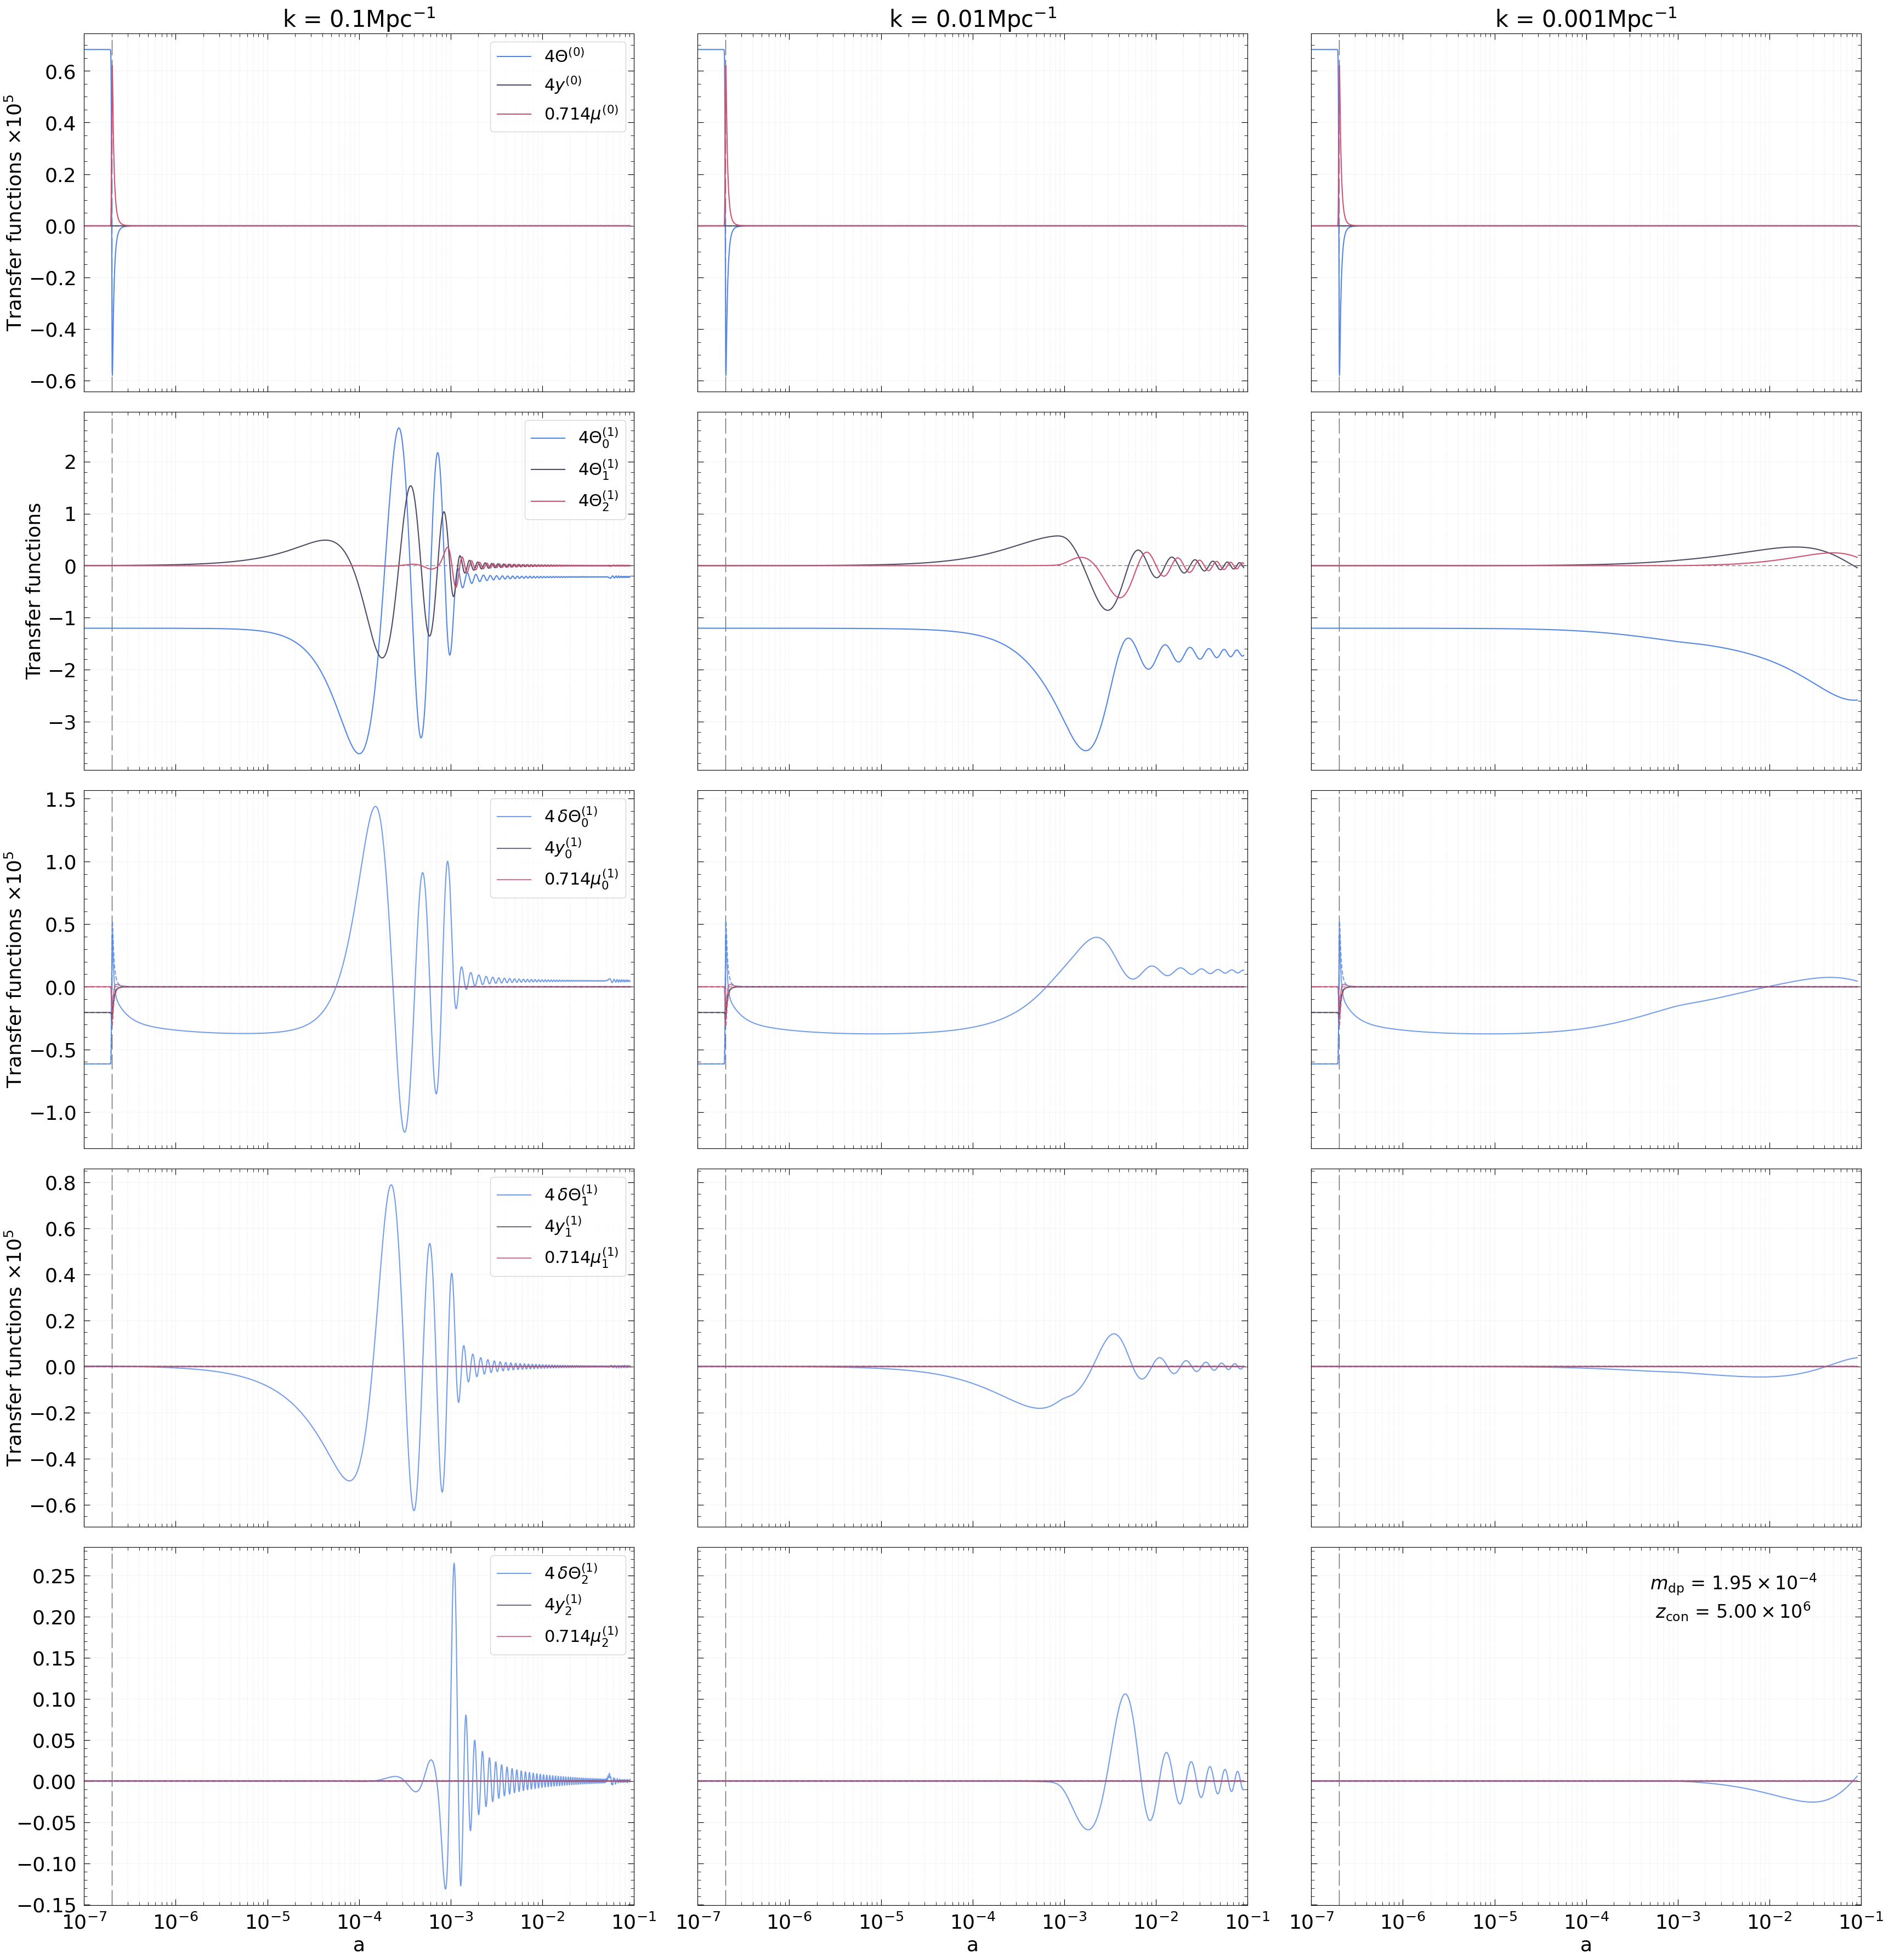

In [70]:



m_dp = 0.000195304 
# Plot Analytical Spectra

plot_transfer_functions(a, theta, dtheta, y, mu, colors, zcon[0], m_dp, dtheta_tc0, y_tc0, mu_tc0)


In [51]:
z1 = []
dtheta_tc1 = []
y_tc1 = []
mu_tc1 = []


for kv in kv_values:
    z1, _theta, _y, _mu = extract_tightcoupling_approx("../Data/Dark-photons/outputs_dp_tc2/outputs-dp1.1_ph",ell,150,kv )

    dtheta_tc1.append(_theta)
    y_tc1.append(_y)
    mu_tc1.append(_mu)

 mu  0 comes from column  7
 mu  1 comes from column  8
 mu  2 comes from column  9
 mu  0 comes from column  7
 mu  1 comes from column  8
 mu  2 comes from column  9
 mu  0 comes from column  7
 mu  1 comes from column  8
 mu  2 comes from column  9


In [52]:
theta_1 = []
y_1 = []
mu_1 = []
a_1 = []
dtheta_1 = []

for kv in kv_values:
    zt, th, yy, m, dth = extract_state_scattering_basis("../Data/Dark-photons/output_dp_ell/outputs-dp1.1_ph/batch/FH/yn_T_aniso_system", ell, 150, kv )
   
    #zt, th, yy, m, dth = extract_state_scattering_basis("../Data/Dark-photons/output_dp_tfph2/outputs-dp1.1_ph/batch/FH/yn_T_aniso_system", ell, 150, kv )
    #zt, th, yy, m, dth = extract_state_scattering_basis("../Data/Dark-photons/dp-aniso1.1/", ell, kv )
    
    theta_1.append(th)
    y_1.append(yy)
    mu_1.append(m)
    a_1.append(zt)
    dtheta_1.append(dth)

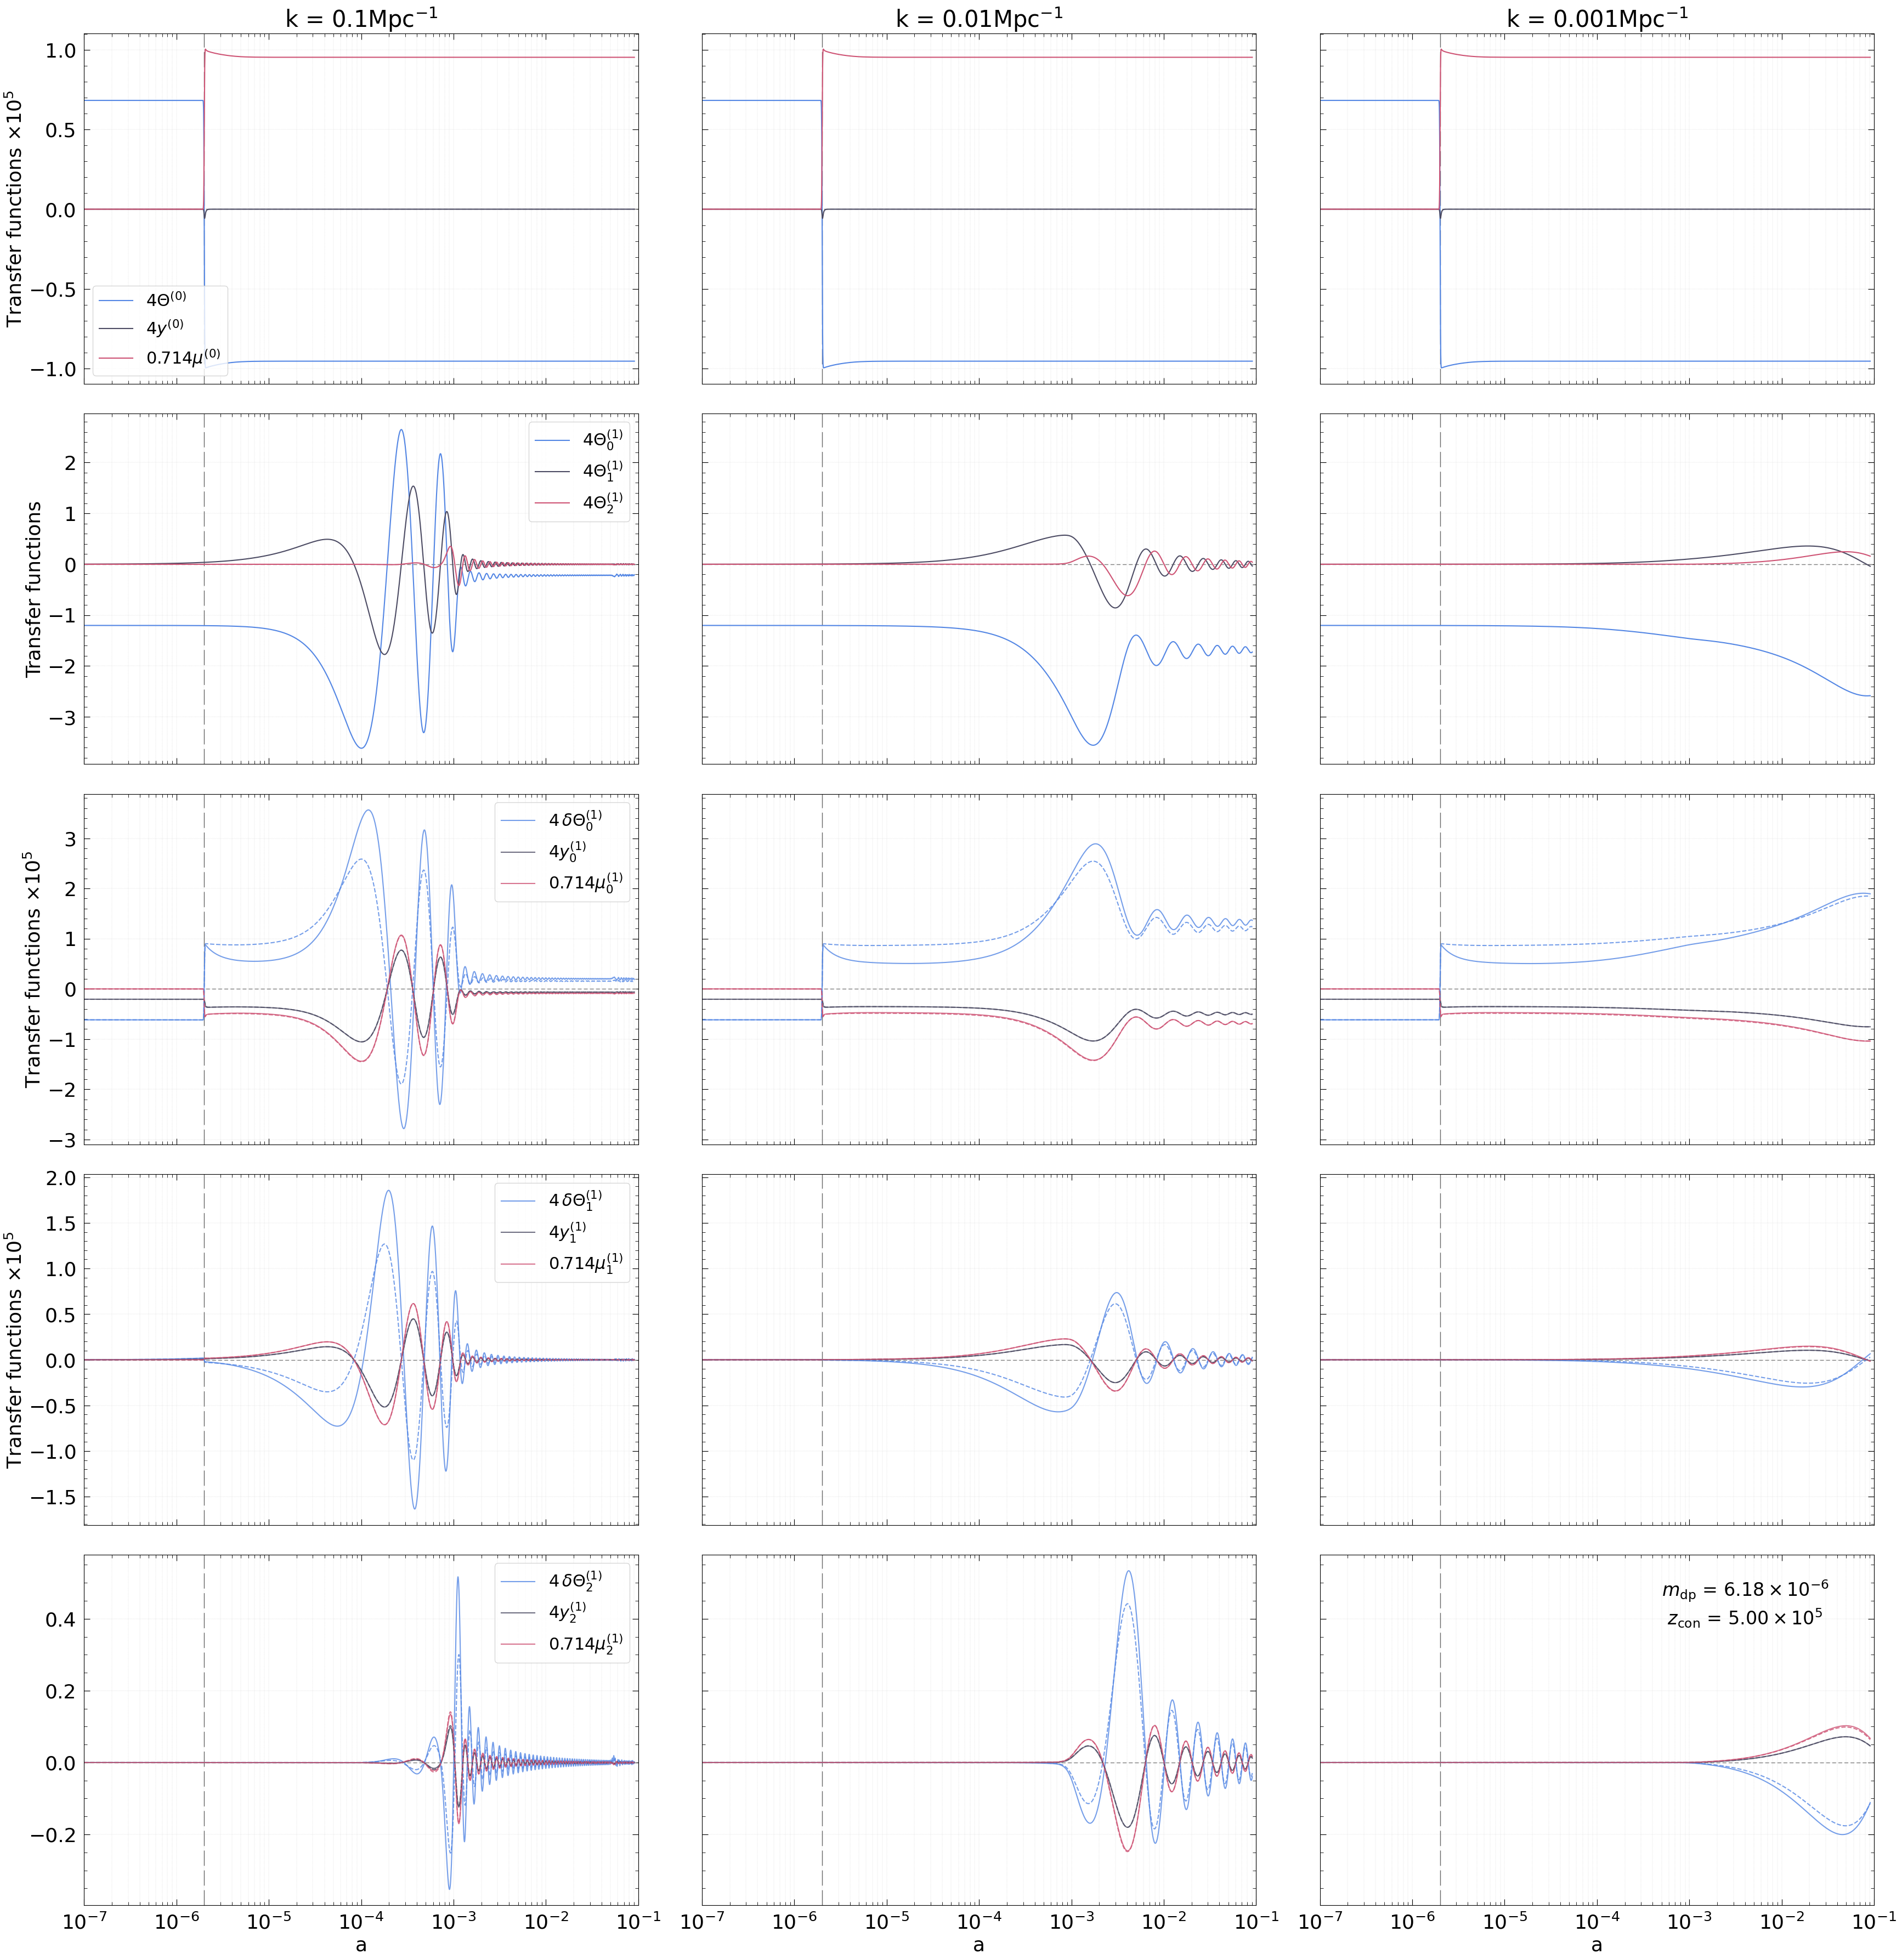

In [71]:
m_dp = 6.17608e-06

plot_transfer_functions(a_1, theta_1, dtheta_1, y_1, mu_1, colors, zcon[1], m_dp, dtheta_tc1, y_tc1, mu_tc1)

In [54]:
z2 = []
dtheta_tc2 = []
y_tc2 = []
mu_tc2 = []


for kv in kv_values:
    z2, _theta, _y, _mu = extract_tightcoupling_approx("../Data/Dark-photons/outputs_dp_tc2/outputs-dp1.2_ph",ell,150,kv )

    dtheta_tc2.append(_theta)
    y_tc2.append(_y)
    mu_tc2.append(_mu)

 mu  0 comes from column  7
 mu  1 comes from column  8
 mu  2 comes from column  9
 mu  0 comes from column  7
 mu  1 comes from column  8
 mu  2 comes from column  9
 mu  0 comes from column  7
 mu  1 comes from column  8
 mu  2 comes from column  9


In [55]:
theta_2 = []
y_2 = []
mu_2 = []
a_2 = []
dtheta_2 = []

for kv in kv_values:
    zt, th, yy, m, dth = extract_state_scattering_basis("../Data/Dark-photons/output_dp_ell/outputs-dp1.2_ph/batch/FH/yn_T_aniso_system/", ell, 150, kv )

    #zt, th, yy, m, dth = extract_state_scattering_basis("../Data/Dark-photons/dp-aniso1.2/", ell, kv )
    #zt, th, yy, m, dth = extract_state_scattering_basis("../Data/Dark-photons/output_dp_tfph2/outputs-dp1.2_ph/batch/FH/yn_T_aniso_system/", ell, 150, kv )
    
    theta_2.append(th)
    y_2.append(yy)
    mu_2.append(m)
    a_2.append(zt)
    dtheta_2.append(dth)

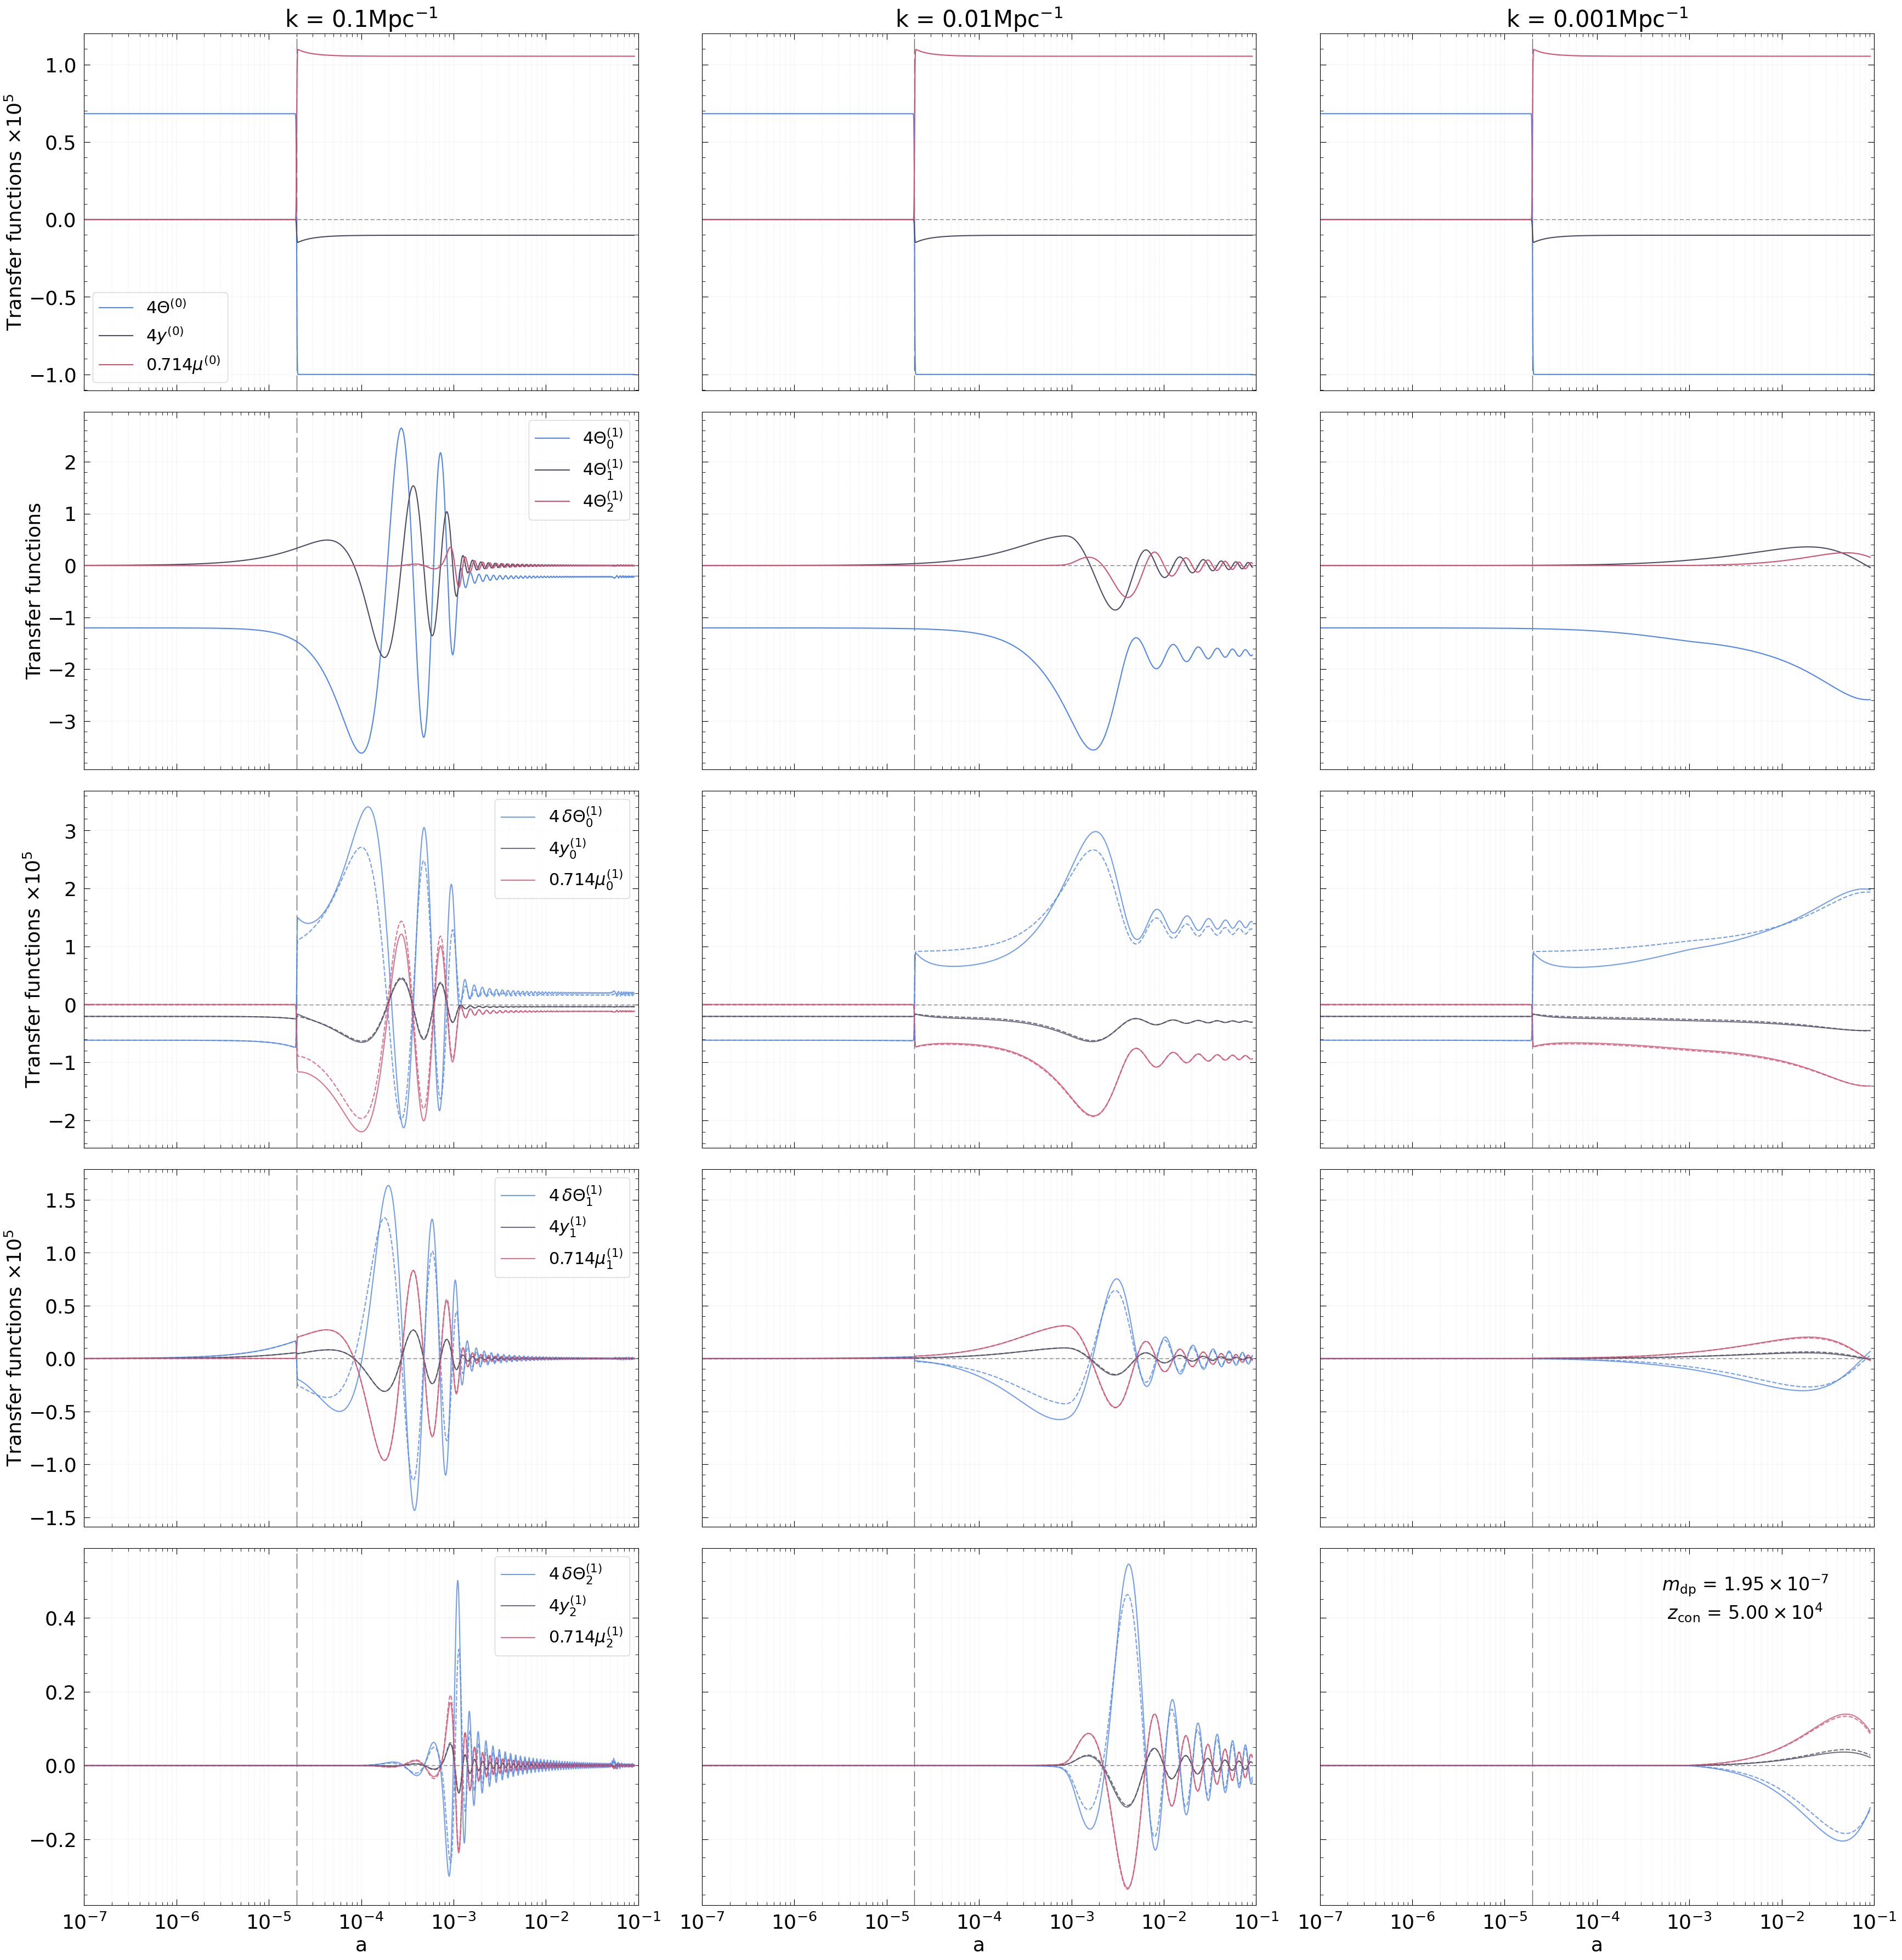

In [72]:
m_dp = 1.9531e-07

plot_transfer_functions(a_2, theta_2, dtheta_2, y_2, mu_2, colors, zcon[2], m_dp, dtheta_tc2, y_tc2, mu_tc2)

In [57]:
z3 = []
display_javascripttheta_tc3 = []
y_tc3 = []
mu_tc3 = []
dtheta_tc3 = []


for kv in kv_values:
    z3, _theta, _y, _mu = extract_tightcoupling_approx("../Data/Dark-photons/outputs_dp_tc2/outputs-dp1.3_ph",ell,150,kv )

    dtheta_tc3.append(_theta)
    y_tc3.append(_y)
    mu_tc3.append(_mu)

 mu  0 comes from column  7
 mu  1 comes from column  8
 mu  2 comes from column  9
 mu  0 comes from column  7
 mu  1 comes from column  8
 mu  2 comes from column  9
 mu  0 comes from column  7
 mu  1 comes from column  8
 mu  2 comes from column  9


In [58]:


theta_3 = []
y_3 = []
mu_3 = []
a_3 = []
dtheta_3 = []

for kv in kv_values:
    #zt, th, yy, m, dth = extract_state_scattering_basis("../Data/Dark-photons/dp-aniso1.3/", ell, kv )
    #zt, th, yy, m, dth = extract_state_scattering_basis("../Data/Dark-photons/output_dp_tfph2/outputs-dp1.3_ph/batch/FH/yn_T_aniso_system", ell, 150, kv )
    zt, th, yy, m, dth = extract_state_scattering_basis("../Data/Dark-photons/output_dp_ell/outputs-dp1.3_ph/batch/FH/yn_T_aniso_system", ell, 150, kv )


    theta_3.append(th)
    y_3.append(yy)
    mu_3.append(m)
    a_3.append(zt)
    dtheta_3.append(dth)

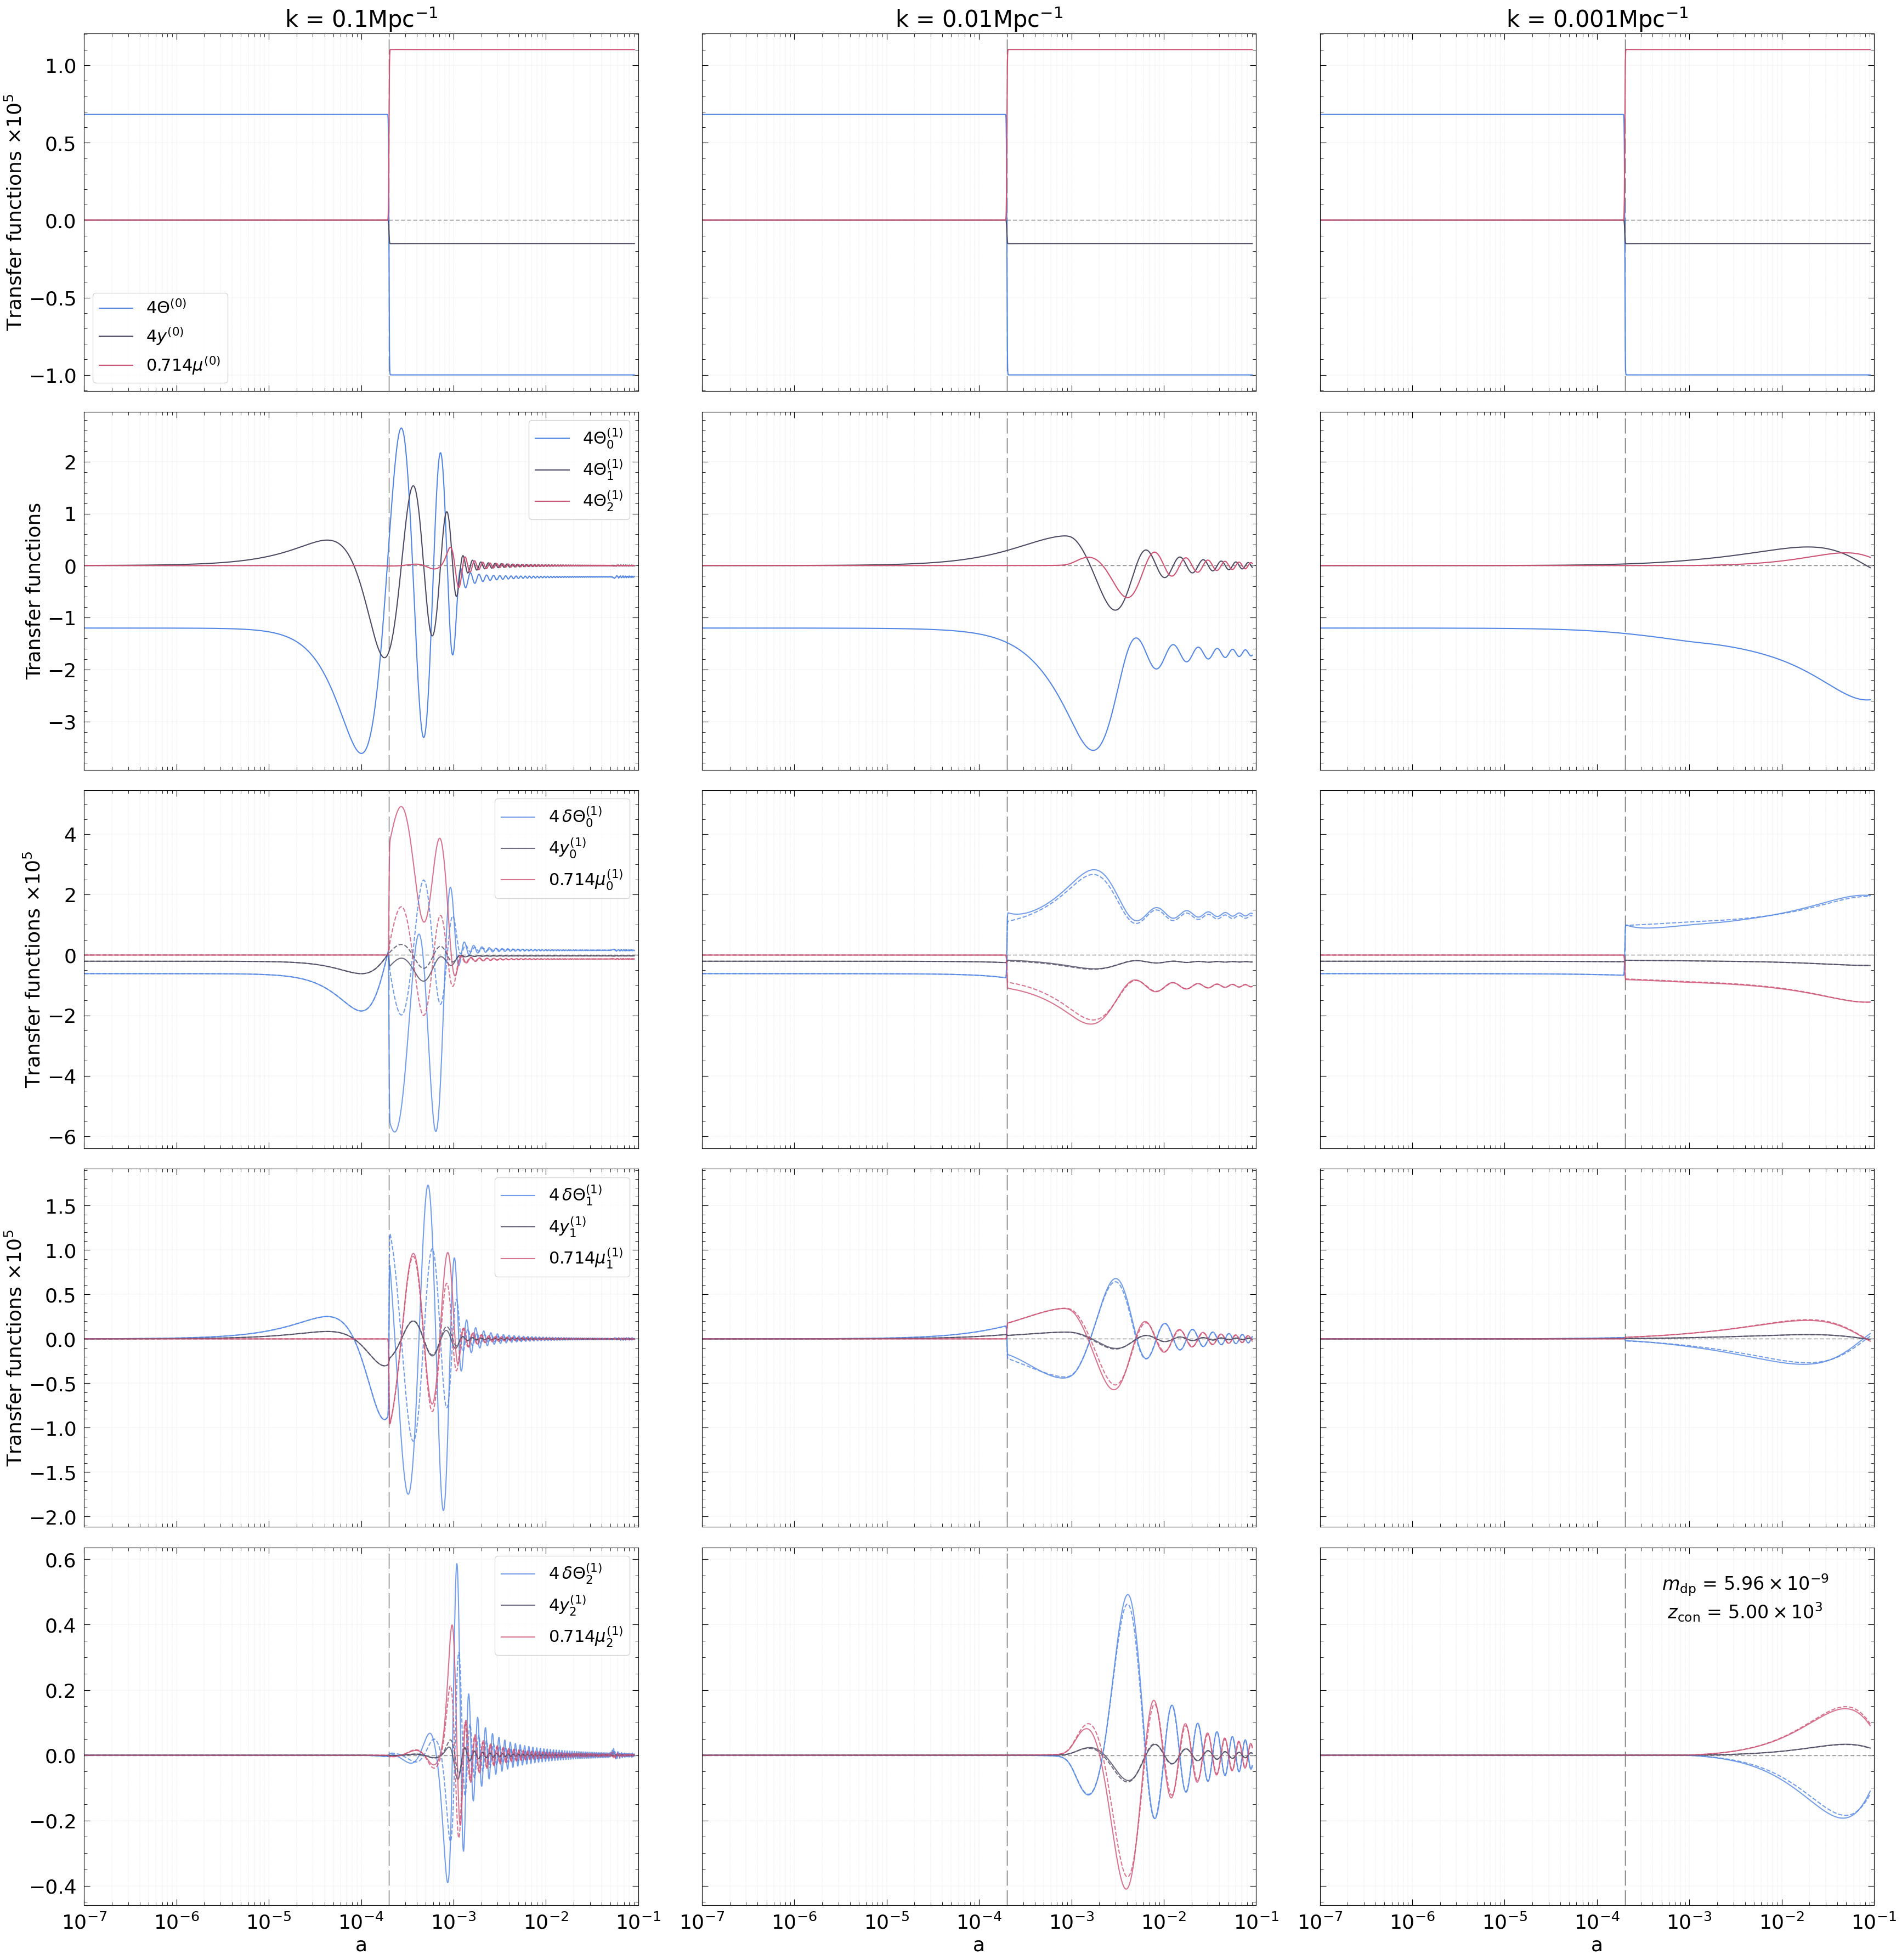

In [73]:
m_dp = 5.9625e-09

plot_transfer_functions(a_3, theta_3, dtheta_3, y_3, mu_3, colors, zcon[3], m_dp, dtheta_tc3, y_tc3, mu_tc3)

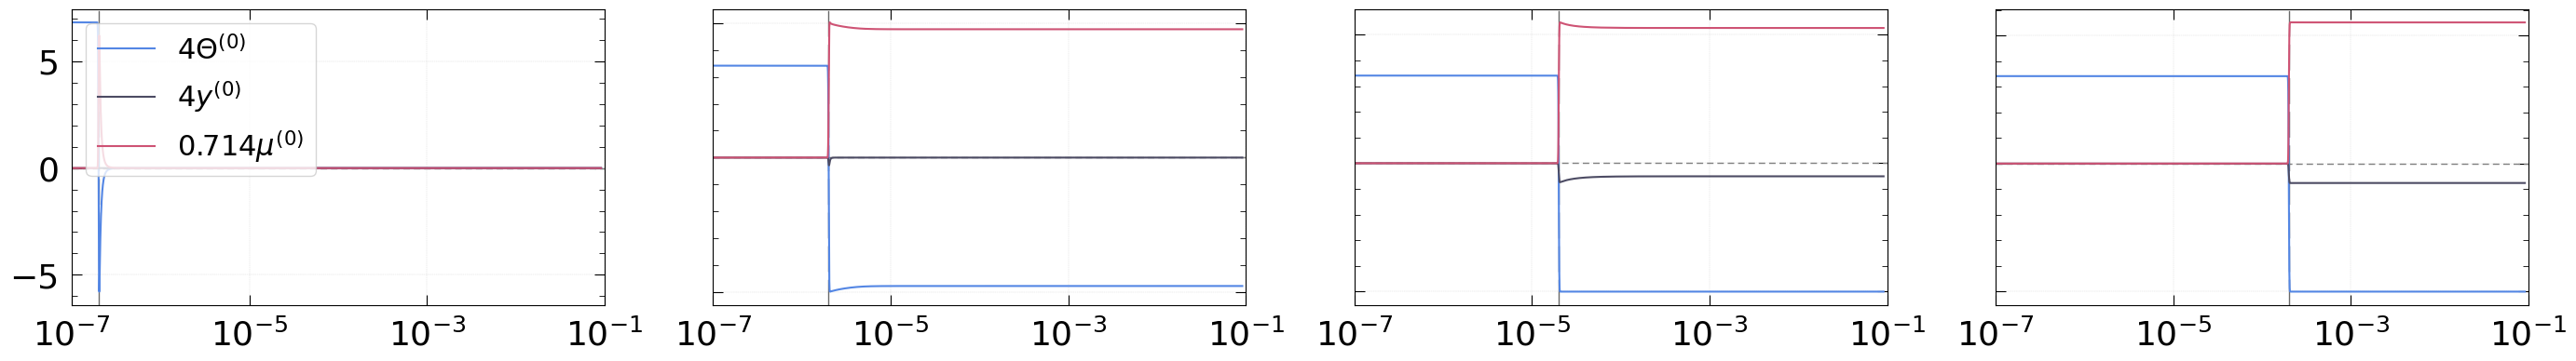

In [60]:

fig, ax1 = plt.subplots(1, 4, figsize=mplt.set_size(mplt.width*4, 1, (1,4)), sharey='col')
fig.subplots_adjust(hspace=0, wspace=0)

i=0
for ax in ax1.flat:
    mplt.set_ticks(ax)
    mplt.set_labels(ax, x_label=None, x_log=True, y_label=None, y_log=False, title=None)
    ax.axhline(y=0, color='gray', linewidth=1, linestyle=(0, (5, 3)))
    ax.axvline(x= 1 / (1+zcon[i]), color='dimgray', linestyle=(0, (20, 6)), linewidth=1)
    ax.set_xlim(1e-7, 1e-1)
    i+=1

ax1[0].plot(a[0], 4.0*theta[0][0]*1e6, label="$4\\Theta^{(0)}$", color=colors[0], linestyle="-")
ax1[0].plot(a[0], 4.0*y[0][0]*1e6, label="$4y^{(0)}$", color=colors[1], linestyle="-")
ax1[0].plot(a[0], 1/1.401*mu[0][0]*1e6, label="$0.714\\mu^{(0)}$", color=colors[2], linestyle="-")
ax1[1].plot(a[0], 4.0*theta_1[0][0]*1e6, label="$4\\Theta^{(0)}$", color=colors[0], linestyle="-")
ax1[1].plot(a[0], 4.0*y_1[0][0]*1e6, label="$4y^{(0)}$", color=colors[1], linestyle="-")
ax1[1].plot(a[0], 1/1.401*mu_1[0][0]*1e6, label="$0.714\\mu^{(0)}$", color=colors[2], linestyle="-")
ax1[2].plot(a[0], 4.0*theta_2[0][0]*1e6, label="$4\\Theta^{(0)}$", color=colors[0], linestyle="-")
ax1[2].plot(a[0], 4.0*y_2[0][0]*1e6, label="$4y^{(0)}$", color=colors[1], linestyle="-")
ax1[2].plot(a[0], 1/1.401*mu_2[0][0]*1e6, label="$0.714\\mu^{(0)}$", color=colors[2], linestyle="-")
ax1[3].plot(a[0], 4.0*theta_3[0][0]*1e6, label="$4\\Theta^{(0)}$", color=colors[0], linestyle="-")
ax1[3].plot(a[0], 4.0*y_3[0][0]*1e6, label="$4y^{(0)}$", color=colors[1], linestyle="-")
ax1[3].plot(a[0], 1/1.401*mu_3[0][0]*1e6, label="$0.714\\mu^{(0)}$", color=colors[2], linestyle="-")

 # Remove y tick labels for middle and right columns

for col in range(1, 4):
    ax1[col].tick_params(labelleft=False)   

ax1[0].legend()

plt.tight_layout() 